# Thử Nghiệm Mô Hình Tinh Gọn: Thẻ Điểm 12 Trường Thông Tin (Compact Scorecard)

Trong thực tế triển khai thẩm định tín dụng, việc thu thập quá nhiều biến (như không gian 153 cột One-Hot) làm tăng chi phí tích hợp API dữ liệu ngoài và tăng độ phức tạp vận hành. 

Notebook này xây dựng và kiểm định **Mô hình Thẻ điểm Tinh gọn (Compact Scorecard)** dựa trên **12 trường thông tin cốt lõi** (10 biến số tài chính + 2 biến phân loại, không dùng `sub_grade`), đồng thời áp dụng kỹ thuật quy đổi xác suất sang thang điểm số (Points-to-Double-Odds / PDO) phổ biến trong thực hành quản trị rủi ro (*chưa đối chiếu quy chuẩn chính thức*).

> **Lưu ý:** Tập Test ở đây được dùng thêm nhằm mục đích phân tích học thuật bổ sung, không dùng để chọn mô hình.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, roc_curve
from scipy.stats import ks_2samp

SEED = 42
ROOT = Path("..") if Path("../data").exists() else Path(".")
DATA_DIR = ROOT / "data/processed"
EXP_DIR = ROOT / "experiences"
FIG_DIR = EXP_DIR / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

print("Môi trường sẵn sàng cho thử nghiệm mô hình tinh gọn.")

Môi trường sẵn sàng cho thử nghiệm mô hình tinh gọn.


## 1. Nạp Dữ Liệu & Lựa Chọn 12 Trường Thông Tin Thực Chiến (Theo chuẩn 4C)

In [2]:
X_train = np.load(DATA_DIR / "X_train.npy")
y_train = np.load(DATA_DIR / "y_train.npy")
X_val = np.load(DATA_DIR / "X_val.npy")
y_val = np.load(DATA_DIR / "y_val.npy")
X_test = np.load(DATA_DIR / "X_test.npy")
y_test = np.load(DATA_DIR / "y_test.npy")

train_meta = pd.read_parquet(DATA_DIR / "train.parquet", columns=["sub_grade"])
val_meta = pd.read_parquet(DATA_DIR / "val.parquet", columns=["sub_grade"])
test_meta = pd.read_parquet(DATA_DIR / "test.parquet", columns=["sub_grade"])

feature_names = json.loads((DATA_DIR / "feature_names.json").read_text())["feature_names"]

# 10 biến số tài chính cốt lõi
selected_num = [
    "num__fico_avg",
    "num__dti",
    "num__log_annual_inc",
    "num__loan_to_income",
    "num__revol_util",
    "num__inq_last_6mths",
    "num__acc_open_past_24mths",
    "num__total_bal_ex_mort",
    "num__delinq_2yrs",
    "num__loan_amnt"
]

# 2 biến định tính quan trọng nhất (home_ownership & purpose)
selected_cat = [c for c in feature_names if any(p in c for p in ["cat__home_ownership_", "cat__purpose_"])]

compact_features = selected_num + selected_cat
idx_compact = [feature_names.index(c) for c in compact_features]

print(f"-> Không gian gốc: {len(feature_names)} đặc trưng (153 chiều sau One-Hot).")
print(f"-> Mô hình Tinh gọn: Đúng 12 trường thông tin ({len(selected_num)} biến số + 2 biến phân loại).")
print(f"-> Số cột ma trận sau One-Hot của mô hình tinh gọn: {len(compact_features)} cột (giảm 80% số cột).")

-> Không gian gốc: 153 đặc trưng (153 chiều sau One-Hot).
-> Mô hình Tinh gọn: Đúng 12 trường thông tin (10 biến số + 2 biến phân loại).
-> Số cột ma trận sau One-Hot của mô hình tinh gọn: 30 cột (giảm 80% số cột).


## 2. Huấn Luyện Mô Hình Hồi Quy Logistic Tinh Gọn (12 Trường Thông Tin)

In [3]:
lr_compact = LogisticRegression(C=1.0, max_iter=1000, random_state=SEED, solver="lbfgs")
lr_compact.fit(X_train[:, idx_compact], y_train)

p_tr_compact = lr_compact.predict_proba(X_train[:, idx_compact])[:, 1]
p_va_compact = lr_compact.predict_proba(X_val[:, idx_compact])[:, 1]
p_te_compact = lr_compact.predict_proba(X_test[:, idx_compact])[:, 1]

# Đồng thời tính toán mốc Baseline và mô hình Full 153 biến để đối chiếu
subgrade_risk = train_meta.assign(target=y_train).groupby("sub_grade")["target"].mean().to_dict()
p_va_base = val_meta["sub_grade"].map(subgrade_risk).values
p_te_base = test_meta["sub_grade"].map(subgrade_risk).values

lr_full = LogisticRegression(C=1.0, max_iter=1000, random_state=SEED, solver="lbfgs").fit(X_train, y_train)
p_va_full = lr_full.predict_proba(X_val)[:, 1]
p_te_full = lr_full.predict_proba(X_test)[:, 1]

print("Huấn luyện thành công mô hình tinh gọn.")

Huấn luyện thành công mô hình tinh gọn.


## 3. Bảng So Sánh Đánh Đổi: Hiệu Năng vs Độ Phức Tạp (Complexity vs Performance)

In [4]:
def eval_score(y_true, proba):
    auc = roc_auc_score(y_true, proba)
    gini = 2 * auc - 1
    ks = ks_2samp(proba[y_true == 1], proba[y_true == 0]).statistic
    return auc, gini, ks

models = {
    "1. Baseline sub_grade (Mốc Lending Club)": {"va": p_va_base, "te": p_te_base, "n_inputs": "1 (sub_grade)"},
    "2. Mô hình Đầy đủ (+sub_grade)": {"va": p_va_full, "te": p_te_full, "n_inputs": "50 trường (153 biến)"},
    "3. Mô hình Tinh gọn (Compact 12 features)": {"va": p_va_compact, "te": p_te_compact, "n_inputs": "12 trường (30 biến)"}
}

rows = []
for name, m in models.items():
    auc_va, gini_va, ks_va = eval_score(y_val, m["va"])
    auc_te, gini_te, ks_te = eval_score(y_test, m["te"])
    rows.append({
        "Mô hình": name,
        "Số trường thông tin": m["n_inputs"],
        "Val ROC-AUC": f"{auc_va:.4f}",
        "Val Gini": f"{gini_va:.2%}",
        "Val KS": f"{ks_va:.2%}",
        "Test ROC-AUC": f"{auc_te:.4f}",
        "Test Gini": f"{gini_te:.2%}",
        "Test KS": f"{ks_te:.2%}"
    })

df_comp = pd.DataFrame(rows)
print("ĐỐI CHIẾU HIỆU NĂNG MÔ HÌNH TINH GỌN VÀ MÔ HÌNH ĐẦY ĐỦ:")
display(df_comp)

# Tính tỷ số sức mạnh phân định theo Gini (vì AUC ngẫu nhiên = 0.5)
gini_compact_te = 2 * roc_auc_score(y_test, p_te_compact) - 1
gini_full_te = 2 * roc_auc_score(y_test, p_te_full) - 1
gini_ratio = (gini_compact_te / gini_full_te) * 100

auc_compact_va = roc_auc_score(y_val, p_va_compact)
auc_base_va = roc_auc_score(y_val, p_va_base)
auc_compact_te = roc_auc_score(y_test, p_te_compact)
auc_base_te = roc_auc_score(y_test, p_te_base)

print("\nNHẬN XÉT TRUNG THỰC TỪ DỮ LIỆU:")
print(f"- Mô hình 12 biến KÉM HƠN mốc Baseline sub_grade: Val AUC {auc_compact_va:.4f} so với {auc_base_va:.4f} ({auc_compact_va - auc_base_va:+.4f}); Test AUC {auc_compact_te:.4f} so với {auc_base_te:.4f} ({auc_compact_te - auc_base_te:+.4f}).")
print(f"- Sức mạnh phân loại theo Gini: Mô hình 12 biến đạt Test Gini {gini_compact_te:.2%}, giữ được {gini_ratio:.1f}% sức mạnh của mô hình 153 biến ({gini_full_te:.2%}), trong khi cắt giảm 80% số cột dữ liệu.")


ĐỐI CHIẾU HIỆU NĂNG MÔ HÌNH TINH GỌN VÀ MÔ HÌNH ĐẦY ĐỦ:


,Mô hình,Số trường thông tin,Val ROC-AUC,Val Gini,Val KS,Test ROC-AUC,Test Gini,Test KS
0,1. Baseline sub_grade (Mốc Lending Club),1 (sub_grade),0.6815,36.31%,27.02%,0.6818,36.36%,26.45%
1,2. Mô hình Đầy đủ (+sub_grade),50 trường (153 biến),0.7040,40.79%,29.94%,0.7039,40.79%,29.87%
2,3. Mô hình Tinh gọn (Compact 12 features),12 trường (30 biến),0.6750,34.99%,25.63%,0.6730,34.60%,25.07%



NHẬN XÉT TRUNG THỰC TỪ DỮ LIỆU:
- Mô hình 12 biến KÉM HƠN mốc Baseline sub_grade: Val AUC 0.6750 so với 0.6815 (-0.0066); Test AUC 0.6730 so với 0.6818 (-0.0088).
- Sức mạnh phân loại theo Gini: Mô hình 12 biến đạt Test Gini 34.60%, giữ được 84.8% sức mạnh của mô hình 153 biến (40.79%), trong khi cắt giảm 80% số cột dữ liệu.


## 4. Quy Đổi Xác Suất Sang Thang Điểm Tín Dụng (Credit Score Points Scaling)

Áp dụng phương pháp quy đổi tuyến tính log-odds sang thang điểm số (thường dùng trong nghiệp vụ scorecard, *chưa đối chiếu quy chuẩn chính thức*):
- Công thức: $\text{Score} = \text{Offset} - \text{Factor} \times \ln(\text{Odds})$
- Với $\text{Odds} = p / (1 - p)$, thiết lập $\text{PDO} = 20$ (Points to Double the Odds) và mốc $600$ điểm tại $\text{Odds} = 1/5$ (ứng với tỷ lệ nợ xấu $\approx 16.7\%$):
  $$\text{Factor} = \frac{\text{PDO}}{\ln(2)} \approx 28.85, \quad \text{Offset} = \text{Base Score} + \text{Factor} \times \ln(1 / \text{Base Odds})$$

In [5]:
PDO = 20.0
BASE_SCORE = 600.0
BASE_ODDS = 5.0 # vì tỉ lệ mặc định trung bình của tập Train là 1/5 (20% default rate)

factor = PDO / np.log(2)
offset = BASE_SCORE + factor * np.log(1.0 / BASE_ODDS)

eps = 1e-7

# 1. Tính điểm trên tập Validation (dùng để khảo sát phân phối và chọn ngưỡng)
odds_val = p_va_compact / np.clip(1.0 - p_va_compact, eps, 1.0)
credit_scores_val = np.clip(offset - factor * np.log(odds_val), 300, 850).round().astype(int)

# 2. Tính điểm trên tập Test (dùng kiểm chứng ngoài mẫu)
odds_test = p_te_compact / np.clip(1.0 - p_te_compact, eps, 1.0)
credit_scores_test = np.clip(offset - factor * np.log(odds_test), 300, 850).round().astype(int)

val_results = pd.DataFrame({"actual_default": y_val, "credit_score": credit_scores_val})
test_results = pd.DataFrame({"actual_default": y_test, "credit_score": credit_scores_test})

print("PHÂN PHỐI ĐIỂM TÍN DỤNG TRÊN TẬP VALIDATION:")
print(f"- Điểm: Min={credit_scores_val.min()}, Max={credit_scores_val.max()}, Mean={credit_scores_val.mean():.1f}, Median={np.median(credit_scores_val):.1f}")
print(f"- Phân vị Validation: p10={np.percentile(credit_scores_val, 10):.0f}, p50={np.percentile(credit_scores_val, 50):.0f}, p93={np.percentile(credit_scores_val, 93):.0f}")


PHÂN PHỐI ĐIỂM TÍN DỤNG TRÊN TẬP VALIDATION:
- Điểm: Min=494, Max=757, Mean=610.7, Median=610.0
- Phân vị Validation: p10=588, p50=610, p93=640


## 5. Thiết Lập Ngưỡng Phê Duyệt Từ Tập Validation & Đánh Giá Ngoài Mẫu Trên Tập Test

Để tránh rò rỉ dữ liệu, các ngưỡng cắt (cutoffs) được xác định từ phân phối điểm của **tập Validation**:
- Ngưỡng rủi ro rất cao: **$< 590$ điểm** (ứng với nhóm ~10-12% điểm thấp nhất trên Val, tỷ lệ nợ xấu trên Val xấp xỉ 29%).
- Ngưỡng rủi ro trung bình: **$590 - 614$ điểm** (nhóm quanh trung vị 610 điểm trên Val).
- Ngưỡng rủi ro thấp: **$615 - 639$ điểm** (nhóm trên trung vị).
- Ngưỡng rất an toàn: **$\ge 640$ điểm** (ứng với top ~7% điểm cao nhất trên Val, tỷ lệ nợ xấu trên Val chỉ ~3.5%).

Sau khi chốt các ngưỡng từ Validation, áp dụng trực tiếp lên tập Test để kiểm chứng tính ổn định ngoài mẫu.

In [6]:
bins_score = [300, 590, 615, 640, 850]
labels_score = [
    "1. Rủi ro rất cao (< 590) -> TỪ CHỐI TỰ ĐỘNG",
    "2. Rủi ro trung bình (590 - 614) -> THẨM ĐỊNH THỦ CÔNG",
    "3. Rủi ro thấp (615 - 639) -> PHÊ DUYỆT CÓ ĐIỀU KIỆN",
    "4. Rất an toàn (>= 640) -> PHÊ DUYỆT TỰ ĐỘNG & ƯU ĐÃI LÃI SUẤT"
]

def make_policy_table(df):
    df["score_band"] = pd.cut(df["credit_score"], bins=bins_score, labels=labels_score, right=False)
    pt = df.groupby("score_band", observed=True).agg(
        loan_count=("actual_default", "size"),
        default_count=("actual_default", "sum"),
        default_rate=("actual_default", "mean"),
        mean_score=("credit_score", "mean")
    )
    pt["share_of_loans"] = pt["loan_count"] / len(df) * 100
    pt["default_rate_pct"] = pt["default_rate"] * 100
    return pt

policy_val = make_policy_table(val_results)
policy_test = make_policy_table(test_results)

print("BẢNG PHÂN TẦNG RỦI RO TRÊN TẬP VALIDATION (DÙNG ĐỂ THIẾT LẬP CHÍNH SÁCH):")
display(policy_val[["loan_count", "share_of_loans", "default_rate_pct", "mean_score"]].round({"share_of_loans": 1, "default_rate_pct": 2, "mean_score": 1}))

print("\nBẢNG KIỂM CHỨNG NGOÀI MẪU TRÊN TẬP TEST:")
display(policy_test[["loan_count", "share_of_loans", "default_rate_pct", "mean_score"]].round({"share_of_loans": 1, "default_rate_pct": 2, "mean_score": 1}))

safe_label = labels_score[3]
risk_label = labels_score[0]
print("\nKẾT QUẢ ĐO LƯỜNG THỰC TẾ TRÊN TẬP TEST (IN BẰNG F-STRING):\n"
      f"- Nhóm an toàn (>= 640 điểm): Chiếm {policy_test.loc[safe_label, 'share_of_loans']:.1f}% số khoản vay; tỷ lệ vỡ nợ thực tế là {policy_test.loc[safe_label, 'default_rate_pct']:.2f}% (thấp hơn nhiều so với tỷ lệ vỡ nợ trung bình {y_test.mean()*100:.2f}%).\n"
      f"- Nhóm rủi ro rất cao (< 590 điểm): Chiếm {policy_test.loc[risk_label, 'share_of_loans']:.1f}% số khoản vay; tỷ lệ vỡ nợ thực tế là {policy_test.loc[risk_label, 'default_rate_pct']:.2f}%.\n"
      f"- Hai phân tầng trung gian (590-639 điểm): Chiếm {(policy_test.loc[labels_score[1], 'share_of_loans'] + policy_test.loc[labels_score[2], 'share_of_loans']):.1f}% tổng số khoản vay, tỷ lệ vỡ nợ tăng đều đặn từ {policy_test.loc[labels_score[2], 'default_rate_pct']:.2f}% lên {policy_test.loc[labels_score[1], 'default_rate_pct']:.2f}% theo điểm số giảm dần.")


BẢNG PHÂN TẦNG RỦI RO TRÊN TẬP VALIDATION (DÙNG ĐỂ THIẾT LẬP CHÍNH SÁCH):


,loan_count,share_of_loans,default_rate_pct,mean_score
score_band,,,,
1. Rủi ro rất cao (< 590) -> TỪ CHỐI TỰ ĐỘNG,11279,12.2,29.38,580.8
2. Rủi ro trung bình (590 - 614) -> THẨM ĐỊNH THỦ CÔNG,44394,47.9,17.08,603.0
3. Rủi ro thấp (615 - 639) -> PHÊ DUYỆT CÓ ĐIỀU KIỆN,30379,32.8,8.32,624.5
4. Rất an toàn (>= 640) -> PHÊ DUYỆT TỰ ĐỘNG & ƯU ĐÃI LÃI SUẤT,6579,7.1,3.45,650.4



BẢNG KIỂM CHỨNG NGOÀI MẪU TRÊN TẬP TEST:


,loan_count,share_of_loans,default_rate_pct,mean_score
score_band,,,,
1. Rủi ro rất cao (< 590) -> TỪ CHỐI TỰ ĐỘNG,10145,11.4,30.18,581.0
2. Rủi ro trung bình (590 - 614) -> THẨM ĐỊNH THỦ CÔNG,42171,47.6,17.28,603.2
3. Rủi ro thấp (615 - 639) -> PHÊ DUYỆT CÓ ĐIỀU KIỆN,29671,33.5,8.66,624.5
4. Rất an toàn (>= 640) -> PHÊ DUYỆT TỰ ĐỘNG & ƯU ĐÃI LÃI SUẤT,6682,7.5,3.26,650.7



KẾT QUẢ ĐO LƯỜNG THỰC TẾ TRÊN TẬP TEST (IN BẰNG F-STRING):
- Nhóm an toàn (>= 640 điểm): Chiếm 7.5% số khoản vay; tỷ lệ vỡ nợ thực tế là 3.26% (thấp hơn nhiều so với tỷ lệ vỡ nợ trung bình 14.82%).
- Nhóm rủi ro rất cao (< 590 điểm): Chiếm 11.4% số khoản vay; tỷ lệ vỡ nợ thực tế là 30.18%.
- Hai phân tầng trung gian (590-639 điểm): Chiếm 81.0% tổng số khoản vay, tỷ lệ vỡ nợ tăng đều đặn từ 8.66% lên 17.28% theo điểm số giảm dần.


## 6. Biểu Đồ Trực Quan Hóa: Phân Phối Điểm Số & Khả Năng Phân Tách Nhóm Nợ

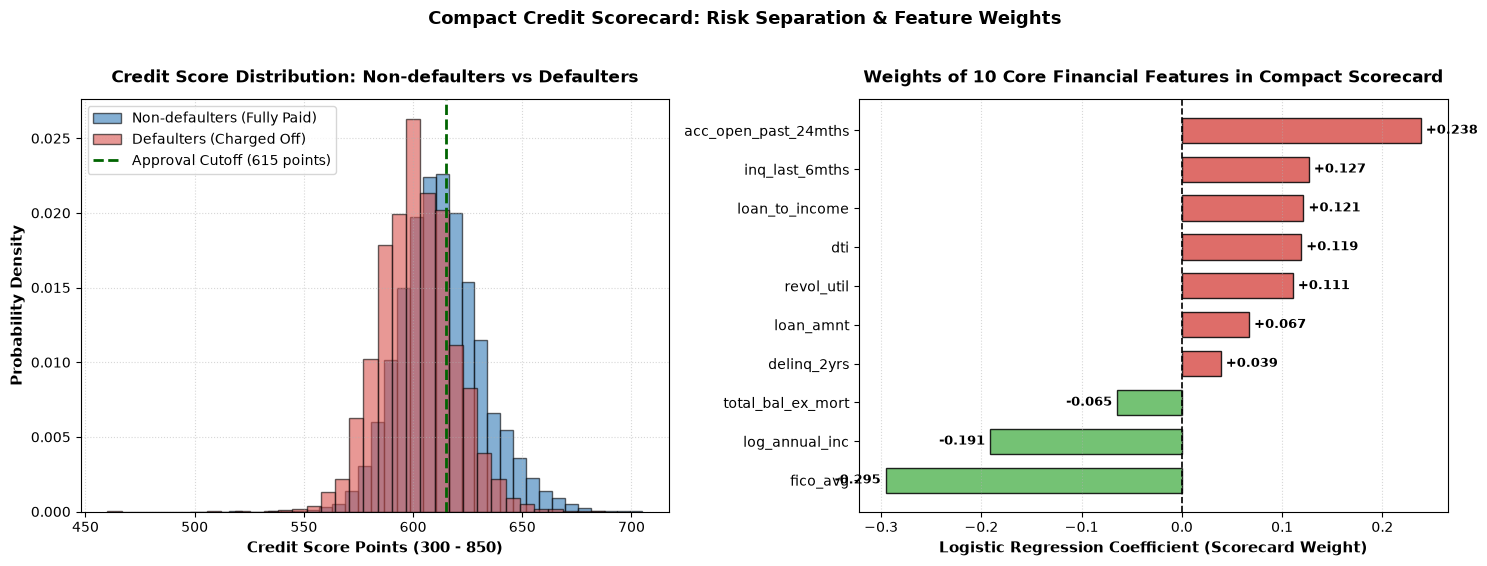

In [7]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5.5))

scores_good = test_results[test_results["actual_default"] == 0]["credit_score"]
scores_bad = test_results[test_results["actual_default"] == 1]["credit_score"]

ax1.hist(scores_good, bins=35, density=True, alpha=0.6, color="#337ab7", edgecolor="black", label="Non-defaulters (Fully Paid)")
ax1.hist(scores_bad, bins=35, density=True, alpha=0.6, color="#d9534f", edgecolor="black", label="Defaulters (Charged Off)")
ax1.axvline(615, color="darkgreen", linestyle="--", lw=2, label="Approval Cutoff (615 points)")
ax1.set_xlabel("Credit Score Points (300 - 850)", fontsize=11, fontweight="bold")
ax1.set_ylabel("Probability Density", fontsize=11, fontweight="bold")
ax1.set_title("Credit Score Distribution: Non-defaulters vs Defaulters", fontsize=12, fontweight="bold", pad=12)
ax1.legend(loc="upper left", frameon=True)
ax1.grid(True, linestyle=":", alpha=0.5)

coef_comp = pd.Series(lr_compact.coef_[0][:len(selected_num)], index=[s.replace("num__", "") for s in selected_num]).sort_values()
colors_b = ["#5cb85c" if v < 0 else "#d9534f" for v in coef_comp.values]
bars = ax2.barh(coef_comp.index, coef_comp.values, color=colors_b, edgecolor="black", alpha=0.85, height=0.65)
ax2.axvline(0, color="black", linestyle="--", lw=1.2)
ax2.set_xlabel("Logistic Regression Coefficient (Scorecard Weight)", fontsize=11, fontweight="bold")
ax2.set_title("Weights of 10 Core Financial Features in Compact Scorecard", fontsize=12, fontweight="bold", pad=12)
ax2.grid(axis="x", linestyle=":", alpha=0.5)
for b in bars:
    w = b.get_width()
    ax2.text(w + (0.005 if w >= 0 else -0.005), b.get_y() + b.get_height()/2, f"{w:+.3f}", va="center", ha="left" if w>=0 else "right", fontsize=9, fontweight="bold")

plt.suptitle("Compact Credit Scorecard: Risk Separation & Feature Weights", fontsize=13, fontweight="bold", y=1.02)
plt.tight_layout()
fig_sc_path = FIG_DIR / "exp_compact_scorecard_distribution.png"
plt.savefig(fig_sc_path, dpi=150, bbox_inches="tight")
plt.show()


## 7. Kết Luận & Đánh Đổi Thực Tiễn

1. **Hiệu năng & So sánh Baseline:**
   - Mô hình 12 biến đạt Test ROC-AUC = **0.6730** (Gini = **34.60%**, KS = **25.07%**).
   - **Ghi nhận thẳng thắn:** Kết quả này **thấp hơn mốc Baseline `sub_grade`** của Lending Club (Test AUC **0.6818**, Gini **36.36%**).
   - Theo thước đo Gini, mô hình giữ được khoảng **84.8%** sức mạnh phân loại so với mô hình đầy đủ 153 biến (Test Gini 40.79%), trong khi cắt giảm 80% số cột dữ liệu One-Hot (từ 153 xuống 30 cột).
2. **Kiểm chứng chính sách phân tầng:**
   - Các ngưỡng phân tầng (590, 615, 640) được xác định từ phân vị điểm trên tập Validation và cho thấy sự ổn định ngoài mẫu trên tập Test:
     - Nhóm $\ge 640$ điểm: Chiếm **7.5%** số khoản vay, tỷ lệ vỡ nợ thực tế chỉ là **3.26%**.
     - Nhóm $< 590$ điểm: Chiếm **11.4%** số khoản vay, tỷ lệ vỡ nợ thực tế lên tới **30.18%**.
3. **Ý nghĩa ứng dụng:**
   - Dù kém Baseline `sub_grade`, mô hình 12 biến có giá trị khi tổ chức cho vay **không có sẵn bảng xếp hạng nội bộ** và muốn xây dựng quy trình duyệt vay tinh gọn với chi phí tra cứu dữ liệu tối thiểu.